In [ ]:
# Import required libraries
import time
from types import SimpleNamespace
import requests
import zipfile
import os

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import statsmodels.api as sm
from statsmodels.formula.api import glm
from scipy import stats
from sklearn.metrics import mean_poisson_deviance
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import FunctionTransformer
import tensorflow as tf
from tensorflow import keras
from google.colab import files

from IPython.display import clear_output

from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import (
    FunctionTransformer,
    OrdinalEncoder,
    StandardScaler,
)


In [ ]:
# a helper to allow quick run of notebook
QUICK_MODE = False

def effective_epochs(n):
  if QUICK_MODE:
    print("WARNING: Not running all epochs due to QUICK_MODE")
    return 1
  else:
    return n

In [ ]:
# URL of the zip file
zip_url = "https://people.math.ethz.ch/~wueth/AITools/Data.zip"
zip_file_name = "Data.zip"

if not os.path.exists(zip_file_name):
  print(f"Downloading {zip_file_name}...")
  response = requests.get(zip_url)
  response.raise_for_status() # Raise an exception for HTTP errors

  with open(zip_file_name, "wb") as f:
      f.write(response.content)
else:
  print(f"{zip_file_name} already exists.")

# Unzip the file
print(f"Unzipping {zip_file_name}...")
with zipfile.ZipFile(zip_file_name, 'r') as zip_ref:
    zip_ref.extractall(".") # Extract to the current directory
print("Unzipping complete.")


Data.zip already exists.
Unzipping Data.zip...
Unzipping complete.


In [ ]:
df = pd.read_parquet("Data/freMTPL2freq.parquet")
print(df.info())
df.head()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 678007 entries, 0 to 678006
Data columns (total 14 columns):
 #   Column      Non-Null Count   Dtype   
---  ------      --------------   -----   
 0   IDpol       678007 non-null  float64 
 1   Exposure    678007 non-null  float64 
 2   Area        678007 non-null  category
 3   VehPower    678007 non-null  int32   
 4   VehAge      678007 non-null  int32   
 5   DrivAge     678007 non-null  int32   
 6   BonusMalus  678007 non-null  int32   
 7   VehBrand    678007 non-null  category
 8   VehGas      678007 non-null  category
 9   Density     678007 non-null  int32   
 10  Region      678007 non-null  category
 11  ClaimTotal  678007 non-null  float64 
 12  ClaimNb     678007 non-null  float64 
 13  LearnTest   678007 non-null  object  
dtypes: category(4), float64(4), int32(5), object(1)
memory usage: 41.4+ MB
None


,IDpol,Exposure,Area,VehPower,VehAge,DrivAge,BonusMalus,VehBrand,VehGas,Density,Region,ClaimTotal,ClaimNb,LearnTest
0,4156370.0,0.06,D,6,6,20,100,B2,Regular,525,R82,0.0,0.0,L
1,4006798.0,0.29,E,6,7,29,59,B12,Diesel,2498,R72,0.0,0.0,L
2,6084964.0,0.46,C,7,10,27,68,B1,Diesel,123,R82,0.0,0.0,L
3,2228865.0,0.08,D,4,15,34,50,B2,Regular,1109,R24,0.0,0.0,L
4,4141911.0,1.00,A,5,22,44,50,B3,Diesel,34,R72,0.0,0.0,L


In [ ]:
mtpl = SimpleNamespace(
    training_data_raw = df[df.LearnTest == "L"].reset_index(drop=True),
    testing_data_raw = df[df.LearnTest == "T"].reset_index(drop=True),
)

In [ ]:
def preprocess_mtpl():
  """ for comparability the preprocessing as well as the data is taken from
  https://github.com/wueth/AITools4Actuaries/blob/main/Ch3_02_Poisson_GLM.ipynb"""

  # DrivAge: 31-40 is placed first so it becomes the GLM reference level
  _driv_age_bins = [17, 20, 25, 30, 40, 50, 70, 101]
  _driv_age_labels = ["18-20", "21-25", "26-30", "31-40", "41-50", "51-70", "71+"]
  _driv_age_ref_first = ["31-40"] + [lev for lev in _driv_age_labels if lev != "31-40"]

  # --- preprocessing functions specific for single covariates ---
  def _area_encode(X):
    """Map alphabetical area codes A-F to ordinal integers 1-6."""
    return (X.squeeze().cat.codes + 1.0).to_frame(name="AreaGLM")

  def _vehpower_clip(X):
    """Cap vehicle power at 9 and treat as categorical."""
    return pd.DataFrame({"VehPowerGLM": pd.Categorical(X.squeeze().clip(upper=9))})

  def _vehage_bin(X):
    """Bin vehicle age into three groups: 0-5, 6-12, 12+."""
    return pd.DataFrame({
            "VehAgeGLM": pd.cut(
                X.squeeze(), bins=[-1, 5, 12, 101], labels=["0-5", "6-12", "12+"]
            )})

  def _drivage_bin(X):
      """Bin driver age into seven groups with 31-40 as the reference level."""
      cuts = pd.cut(X.squeeze(), bins=_driv_age_bins, labels=_driv_age_labels)
      return pd.DataFrame(
          {"DrivAgeGLM": pd.Categorical(cuts, categories=_driv_age_ref_first)}
      )

  def _bonusmalus_clip(X):
      """Cap bonus-malus score at 150."""
      return pd.DataFrame({"BonusMalusGLM": X.squeeze().clip(upper=150)})

  def _density_log(X):
      """Log-transform population density."""
      return pd.DataFrame({"DensityGLM": np.log(X.squeeze())})

  def _ft(func, names):
      """Return a FunctionTransformer with fixed output column names."""
      return FunctionTransformer(
          func=func, feature_names_out=lambda self, _: names, check_inverse=False
      )

  # --- assemble the preprocessing pipeline ---
  preprocessor = ColumnTransformer(
    transformers=[
        ("area", _ft(_area_encode, ["AreaGLM"]), ["Area"]),
        ("vehpower", _ft(_vehpower_clip, ["VehPowerGLM"]), ["VehPower"]),
        ("vehage", _ft(_vehage_bin, ["VehAgeGLM"]), ["VehAge"]),
        ("drivage", _ft(_drivage_bin, ["DrivAgeGLM"]), ["DrivAge"]),
        ("bonusmalus", _ft(_bonusmalus_clip, ["BonusMalusGLM"]), ["BonusMalus"]),
        ("density", _ft(_density_log, ["DensityGLM"]), ["Density"]),
        ("passthrough", "passthrough", ["VehBrand", "VehGas", "ClaimNb", "Exposure"]),
    ],
    verbose_feature_names_out=False,
  )
  # Fit preprocessor on learning data only
  preprocessor.set_output(transform="pandas").fit(mtpl.training_data_raw)

  mtpl.training_data = preprocessor.transform(mtpl.training_data_raw).copy()
  mtpl.testing_data = preprocessor.transform(mtpl.testing_data_raw).copy()
preprocess_mtpl()



In [ ]:
# a global list of all models
model_list = []

In [ ]:
glm1 = SimpleNamespace(
    name = "glm1",
  description = "The baseline GLM from AITools4Actuaries",
  train = SimpleNamespace(target = mtpl.training_data["ClaimNb"],
                          exposure = mtpl.training_data['Exposure']),
  test = SimpleNamespace(target = mtpl.testing_data["ClaimNb"],
                         exposure = mtpl.testing_data['Exposure']),
)

glm1.model = glm(
      "ClaimNb ~ DrivAgeGLM + VehBrand + VehGas + DensityGLM + AreaGLM",
      data=mtpl.training_data,
      offset=np.log(mtpl.training_data["Exposure"]),
      family=sm.families.Poisson(),
  )

glm1.results = glm1.model.fit()
print(glm1.results.summary())
model_list.append(glm1)
glm1.train.prediction = glm1.results.predict(mtpl.training_data)
glm1.test.prediction = glm1.results.predict(mtpl.testing_data)


                 Generalized Linear Model Regression Results                  
Dep. Variable:                ClaimNb   No. Observations:               610206
Model:                            GLM   Df Residuals:                   610186
Model Family:                 Poisson   Df Model:                           19
Link Function:                    Log   Scale:                          1.0000
Method:                          IRLS   Log-Likelihood:                -98513.
Date:                Wed, 14 Oct 2026   Deviance:                   1.5138e+05
Time:                        19:20:58   Pearson chi2:                 1.02e+06
No. Iterations:                     7   Pseudo R-squ. (CS):           0.004052
Covariance Type:            nonrobust                                         
                          coef    std err          z      P>|z|      [0.025      0.975]
---------------------------------------------------------------------------------------
Intercept              -3.2590    

In [ ]:
def calculate_deviance(model_run):
  # Calculate in-sample and out-of-sample deviance using sklearn
  # For better visibility we scale with 100
  for dataset_name, dataset in [("Training", model_run.train), ("Testing", model_run.test)]:
    dataset.deviance = 100 * mean_poisson_deviance(
      dataset.target / dataset.exposure,
      dataset.prediction,
      sample_weight=dataset.exposure
    )

    actual_claims = np.asarray(dataset.target).ravel()
    exposure = np.asarray(dataset.exposure).ravel()
    predicted_rates = np.asarray(dataset.prediction).ravel()

    dataset.keras_poisson = np.mean(exposure * ( predicted_rates - actual_claims/exposure * np.log(predicted_rates) ) )

    predicted_claims = predicted_rates * exposure
    relative_scoring = actual_claims.sum() / predicted_claims.sum()
    print(f"{dataset_name} Deviance = {dataset.deviance:.3f} Keras Poisson = {dataset.keras_poisson:.5f}"
      f"  Total Actual Claims: {actual_claims.sum():.2f}"
      f"  Total Predicted Claims: {predicted_claims.sum():.2f}"
      f"  Relative Scoring (Actual / Predicted): {relative_scoring:.4f}")

calculate_deviance(glm1)

# check that we properly reproduce the base case from AITools4Actuaries
assert abs(glm1.train.deviance - 46.954) < 0.0006, f"training deviance is {glm1.train.deviance:.3f}, expected 46.954"
assert abs(glm1.test.deviance - 47.179) < 0.0006, f"test deviance is {glm1.test.deviance:.3f}, expected 47.179"

Training Deviance = 46.954 Keras Poisson = 0.13835  Total Actual Claims: 23738.00  Total Predicted Claims: 23738.00  Relative Scoring (Actual / Predicted): 1.0000
Testing Deviance = 47.179 Keras Poisson = 0.13874  Total Actual Claims: 2645.00  Total Predicted Claims: 2650.74  Relative Scoring (Actual / Predicted): 0.9978


### One-hot Encoding Categorical Features

Now, I'll create one-hot encoded versions of the training and testing dataframes. `pd.get_dummies` will automatically identify and convert categorical columns (object or category dtype) into a numerical format, which can be useful for other modeling approaches.

In [ ]:
features = ["DrivAgeGLM", "VehBrand", "VehGas", "DensityGLM", "AreaGLM"]

# Perform one-hot encoding on training and testing data
# pd.get_dummies automatically handles categorical (object/category) columns
mtpl.training_data_1h = pd.get_dummies(mtpl.training_data[features], drop_first=True, dtype=float)
mtpl.testing_data_1h = pd.get_dummies(mtpl.testing_data[features], drop_first=True, dtype=float)

print(mtpl.training_data_1h.info())

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 610206 entries, 0 to 610205
Data columns (total 19 columns):
 #   Column            Non-Null Count   Dtype  
---  ------            --------------   -----  
 0   DensityGLM        610206 non-null  float64
 1   AreaGLM           610206 non-null  float64
 2   DrivAgeGLM_18-20  610206 non-null  float64
 3   DrivAgeGLM_21-25  610206 non-null  float64
 4   DrivAgeGLM_26-30  610206 non-null  float64
 5   DrivAgeGLM_41-50  610206 non-null  float64
 6   DrivAgeGLM_51-70  610206 non-null  float64
 7   DrivAgeGLM_71+    610206 non-null  float64
 8   VehBrand_B2       610206 non-null  float64
 9   VehBrand_B3       610206 non-null  float64
 10  VehBrand_B4       610206 non-null  float64
 11  VehBrand_B5       610206 non-null  float64
 12  VehBrand_B6       610206 non-null  float64
 13  VehBrand_B10      610206 non-null  float64
 14  VehBrand_B11      610206 non-null  float64
 15  VehBrand_B12      610206 non-null  float64
 16  VehBrand_B13      61

### Keras Feedforward Neural Network Setup

Now, I'll set up a Keras FNN. The network will consist of an input layer, and a dense output layer with `1` unit and `exponential` activation. The exponential activation function is chosen to mimic the log link function used in Poisson GLMs, which is suitable for count data (like claim numbers) as it ensures positive predictions.

In [ ]:
def glm_to_keras(params, keras_columns):
    """Return (kernel, bias) for a Keras Dense(1) layer."""
    p = params.copy()

    # statsmodels/Patsy names -> get_dummies names
    p.index = (p.index
               .str.replace(r"\[T\.(.*?)\]", r"_\1", regex=True))

    bias = p.pop("Intercept")
    kernel = p.reindex(keras_columns)

    if kernel.isna().any():
        raise ValueError(f"Missing GLM parameters: {kernel[kernel.isna()].index.tolist()}")

    return kernel.to_numpy().reshape(-1, 1), np.array([bias])

In [ ]:
# a less verbose training output
class OneLineProgress(keras.callbacks.Callback):
    def on_epoch_end(self, epoch, logs=None):
        val_loss = ""
        if "val_loss" in logs:
            val_loss = f" - val_loss: {logs['val_loss']:.6f}"
        print(
            f"\rEpoch {epoch + 1}/{self.params['epochs']} "
            f"- loss: {logs['loss']:.6f} {val_loss}",
            end="",
            flush=True,
        )

    def on_train_end(self, logs=None):
        print()

In [ ]:
def create_glm_linear_predictor(n_features, initializer):
    features_input = keras.Input(shape=(n_features,), name='features_input')

    init = {}
    if initializer is not None:
      weights, bias = initializer
      init['kernel_initializer'] = keras.initializers.Constant(weights)
      init['bias_initializer'] = keras.initializers.Constant(bias)

    linear_predictor = keras.layers.Dense(1, name='glm_linear_predictor', activation='linear', **init)(features_input)

    return linear_predictor, features_input


def glm_keras(name, data, initializer, split, batch_size, epochs, keep_best, description, seed=1234):
    tf.keras.utils.set_random_seed(seed)
    model_info = SimpleNamespace(
        name=name,
        description=description,
        constructor='glm_keras',
        initializer= initializer.name if initializer else "None",
        split=split,
        batch_size=batch_size,
        epochs=epochs,
        keep_best=keep_best,
        seed=seed,
        train = SimpleNamespace(target = data.training_data["ClaimNb"],
                            exposure = data.training_data['Exposure'],
                            input = data.training_data_1h),
    test = SimpleNamespace(target = data.testing_data["ClaimNb"],
                          exposure = data.testing_data['Exposure'],
                          input = data.testing_data_1h),
    )

    if initializer is not None:
      initializer = glm_to_keras(initializer.results.params, model_info.train.input.columns)

    input_shape = model_info.train.input.shape[1]

    linear_predictor, features_input = create_glm_linear_predictor(input_shape, initializer)


    dense_output = keras.layers.Activation("exponential")(linear_predictor)

    # Create the Keras Model
    model_info.model = keras.Model(inputs=features_input, outputs=dense_output)

    if epochs is not None:
      callbacks = [OneLineProgress()]
      if keep_best:
        callbacks.append(keras.callbacks.EarlyStopping(
          monitor="val_loss" if split else "loss",
          patience=epochs,          # effectively prevents early stopping
          restore_best_weights=True,
        ))

      model_info.model.compile(loss="poisson", optimizer="nadam")
      model_info.history = model_info.model.fit(
        model_info.train.input,
        model_info.train.target / model_info.train.exposure,
        sample_weight=model_info.train.exposure,
        validation_split=split,
        batch_size=batch_size,
        epochs=effective_epochs(epochs),
        verbose=0,
        callbacks=callbacks,
      )
    model_info.train.prediction = model_info.model(model_info.train.input, training=False).numpy()
    model_info.test.prediction = model_info.model(model_info.test.input, training=False).numpy()
    calculate_deviance(model_info)
    return model_info


In [ ]:
glm_keras_control = glm_keras("glm_keras_control", mtpl,
                              initializer=glm1, split=None, batch_size=None, epochs=None, keep_best=False,
                              description="A Keras/Tensorflow model implementing GLM and initialized with GLM coefficients, predicting rate")
glm_keras_control.model.summary()
model_list.append(glm_keras_control)

Training Deviance = 46.954 Keras Poisson = 0.13835  Total Actual Claims: 23738.00  Total Predicted Claims: 23738.00  Relative Scoring (Actual / Predicted): 1.0000
Testing Deviance = 47.179 Keras Poisson = 0.13874  Total Actual Claims: 2645.00  Total Predicted Claims: 2650.74  Relative Scoring (Actual / Predicted): 0.9978


Model: "functional"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ features_input (InputLayer)     │ (None, 19)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ glm_linear_predictor (Dense)    │ (None, 1)              │            20 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation (Activation)         │ (None, 1)              │             0 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 20 (80.00 B)

 Trainable params: 20 (80.00 B)

 Non-trainable params: 0 (0.00 B)

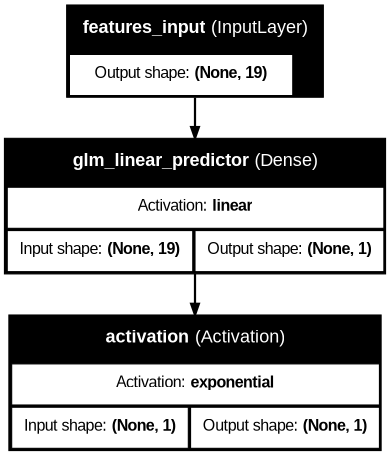

In [ ]:
keras.utils.plot_model(
    glm_keras_control.model,
    show_shapes=True,
    show_layer_names=True,
    show_layer_activations=True,
    expand_nested=True,
    dpi=80,
)

In [ ]:
for batch_size, epochs in [(5000,200), (50000, 2000), (200000, 4000)]:
  for split in [None, 0.1]:
    model_list.append(
        glm_keras("glm_keras_trained", mtpl,
                  initializer=None, split=split, batch_size=batch_size, epochs=epochs, keep_best=True,
                  description=f"A Keras/Tensorflow model implementing GLM"))
    model_list.append(
        glm_keras("glm_keras_train_init", mtpl,
                  initializer=glm1, split=split, batch_size=batch_size, epochs=epochs//10, keep_best=False,
                  description=f"A Keras/Tensorflow model implementing GLM and initialized with GLM coefficients")
        )


Epoch 200/200 - loss: 0.138385 
Training Deviance = 46.961 Keras Poisson = 0.13837  Total Actual Claims: 23738.00  Total Predicted Claims: 23514.94  Relative Scoring (Actual / Predicted): 1.0095
Testing Deviance = 47.200 Keras Poisson = 0.13879  Total Actual Claims: 2645.00  Total Predicted Claims: 2626.10  Relative Scoring (Actual / Predicted): 1.0072
Epoch 20/20 - loss: 0.138371 
Training Deviance = 46.956 Keras Poisson = 0.13836  Total Actual Claims: 23738.00  Total Predicted Claims: 23480.13  Relative Scoring (Actual / Predicted): 1.0110
Testing Deviance = 47.189 Keras Poisson = 0.13876  Total Actual Claims: 2645.00  Total Predicted Claims: 2621.82  Relative Scoring (Actual / Predicted): 1.0088
Epoch 200/200 - loss: 0.138487  - val_loss: 0.137437
Training Deviance = 47.005 Keras Poisson = 0.13849  Total Actual Claims: 23738.00  Total Predicted Claims: 22961.31  Relative Scoring (Actual / Predicted): 1.0338
Testing Deviance = 47.250 Keras Poisson = 0.13893  Total Actual Claims: 2645

In [ ]:
results_data = []

for model_info in model_list:
    train_actual_claims = np.asarray(model_info.train.target).ravel()
    train_exposure = np.asarray(model_info.train.exposure).ravel()
    train_predicted_rates = np.asarray(model_info.train.prediction).ravel()
    train_predicted_claims = train_predicted_rates * train_exposure
    train_relative_scoring = train_actual_claims.sum() / train_predicted_claims.sum()

    test_actual_claims = np.asarray(model_info.test.target).ravel()
    test_exposure = np.asarray(model_info.test.exposure).ravel()
    test_predicted_rates = np.asarray(model_info.test.prediction).ravel()
    test_predicted_claims = test_predicted_rates * test_exposure
    test_relative_scoring = test_actual_claims.sum() / test_predicted_claims.sum()

    results_data.append({
        'name': getattr(model_info, 'name', None),
        'initializer': getattr(model_info, 'initializer', None),
        'batch_size': getattr(model_info, 'batch_size', None),
        'epochs': getattr(model_info, 'epochs', None),
        'keep_best': getattr(model_info, 'keep_best', None),
        'split': getattr(model_info, 'split', None),
        'train_deviance': getattr(model_info.train, 'deviance', None),
        'train_relative_scoring': train_relative_scoring,
        'test_deviance': getattr(model_info.test, 'deviance', None),
        'test_relative_scoring': test_relative_scoring
    })

results_df = pd.DataFrame(results_data)
display(results_df)

,name,initializer,batch_size,epochs,keep_best,split,train_deviance,train_relative_scoring,test_deviance,test_relative_scoring
0,glm1,None,NaN,NaN,None,NaN,46.953720,1.000000,47.178625,0.997834
1,glm_keras_control,glm1,NaN,NaN,False,NaN,46.953720,1.000000,47.178625,0.997834
2,glm_keras_trained,None,5000.0,200.0,True,NaN,46.961176,1.009486,47.200002,1.007197
3,glm_keras_train_init,glm1,5000.0,20.0,False,NaN,46.955965,1.010982,47.188533,1.008840
4,glm_keras_trained,None,5000.0,200.0,True,0.1,47.004507,1.033826,47.250422,1.031282
5,glm_keras_train_init,glm1,5000.0,20.0,False,0.1,46.966795,1.038821,47.196992,1.036688
6,glm_keras_trained,None,50000.0,2000.0,True,NaN,46.954512,1.002555,47.174250,1.000332
7,glm_keras_train_init,glm1,50000.0,200.0,False,NaN,46.954442,1.002634,47.173778,1.000420
8,glm_keras_trained,None,50000.0,2000.0,True,0.1,46.988926,0.994238,47.233213,0.991769
9,glm_keras_train_init,glm1,50000.0,200.0,False,0.1,46.954579,0.998705,47.182034,0.996631


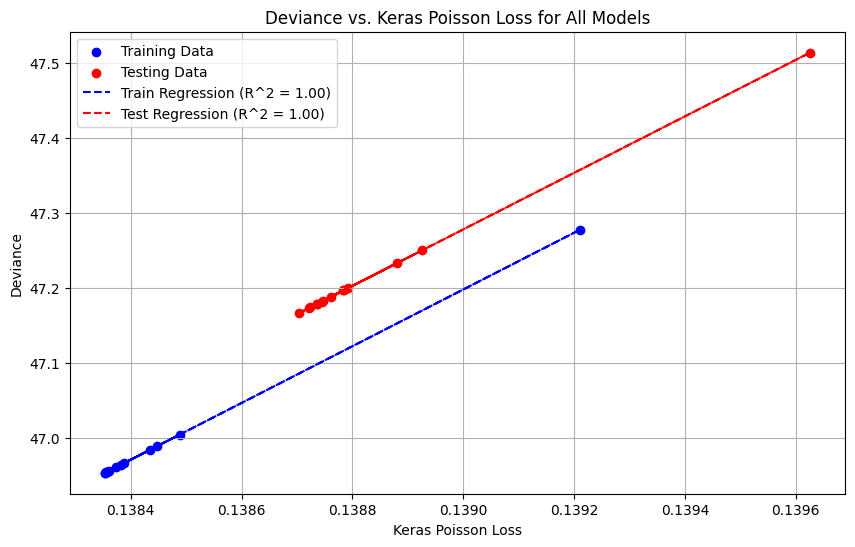

In [ ]:
train_deviance_values = []
train_keras_poisson_values = []
test_deviance_values = []
test_keras_poisson_values = []

for model_info in model_list:
    if hasattr(model_info, 'train') and hasattr(model_info.train, 'deviance') and hasattr(model_info.train, 'keras_poisson') \
       and hasattr(model_info, 'test') and hasattr(model_info.test, 'deviance') and hasattr(model_info.test, 'keras_poisson'):


        if model_info.train.keras_poisson > 0.2: continue

        train_deviance_values.append(model_info.train.deviance)
        train_keras_poisson_values.append(model_info.train.keras_poisson)
        test_deviance_values.append(model_info.test.deviance)
        test_keras_poisson_values.append(model_info.test.keras_poisson)

plt.figure(figsize=(10, 6))
plt.scatter(train_keras_poisson_values, train_deviance_values, color='blue', label='Training Data')
plt.scatter(test_keras_poisson_values, test_deviance_values, color='red', label='Testing Data')

# Calculate and plot regression line for training data
if len(train_keras_poisson_values) > 1:
    slope_train, intercept_train, r_value_train, p_value_train, std_err_train = stats.linregress(train_keras_poisson_values, train_deviance_values)
    plt.plot(train_keras_poisson_values, intercept_train + slope_train * np.array(train_keras_poisson_values), color='blue', linestyle='--', label=f'Train Regression (R^2 = {r_value_train**2:.2f})')

# Calculate and plot regression line for testing data
if len(test_keras_poisson_values) > 1:
    slope_test, intercept_test, r_value_test, p_value_test, std_err_test = stats.linregress(test_keras_poisson_values, test_deviance_values)
    plt.plot(test_keras_poisson_values, intercept_test + slope_test * np.array(test_keras_poisson_values), color='red', linestyle='--', label=f'Test Regression (R^2 = {r_value_test**2:.2f})')

plt.xlabel('Keras Poisson Loss')
plt.ylabel('Deviance')
plt.title('Deviance vs. Keras Poisson Loss for All Models')
plt.legend()
plt.grid(True)
plt.show()

In [ ]:
slope_test, slope_train

(np.float64(377.02221704462494), np.float64(378.5488444556851))

In [ ]:
print(results_df.to_csv())

,name,initializer,batch_size,epochs,keep_best,split,train_deviance,train_relative_scoring,test_deviance,test_relative_scoring
0,glm1,,,,,,46.953719918266934,1.000000000000001,47.178624614533234,0.9978337569528632
1,glm_keras_control,glm1,,,False,,46.953719935124305,1.0000000629130308,47.178624604424336,0.9978338203548712
2,glm_keras_trained,None,5000.0,200.0,True,,46.96117642535264,1.0094858024155853,47.200002496867995,1.0071965766063322
3,glm_keras_train_init,glm1,5000.0,20.0,False,,46.95596468507725,1.010982499992299,47.18853305760207,1.0088397222721763
4,glm_keras_trained,None,5000.0,200.0,True,0.1,47.00450689481654,1.0338262493770947,47.25042193099254,1.0312819368934714
5,glm_keras_train_init,glm1,5000.0,20.0,False,0.1,46.96679549684747,1.0388213993298698,47.19699152858665,1.036688234236075
6,glm_keras_trained,None,50000.0,2000.0,True,,46.95451244373958,1.002555039428058,47.1742495534606,1.0003317047811966
7,glm_keras_train_init,glm1,50000.0,200.0,False,,46.95444188287497,1.0026338

In [ ]:
def write_latex_tables():
  names = {
    "batch_size": "Batch size",
    "epochs": "Epochs",
    "split": "Validation",
    "regularizer": "Regularizer",
    "train_deviance": "Train dev.",
    "train_relative_scoring": "Train O/E",
    "test_deviance": "Test dev.",
    "test_relative_scoring": "Test O/E",
  }

  # MLE-initialised
  table_mle = (
      results_df.loc[results_df["initializer"] == "glm1", names.keys()]
      .sort_values(["batch_size", "split"], na_position="first")
  ).rename(columns=names)

  latex_mle = (
    table_mle.style
    .format({
        "Batch size": "{:.0f}",
        "Epochs": "{:.0f}",
        "Validation": "{:.1f}",
        "Regularizer": "{:.4f}",
        "Train dev.": "{:.3f}",
        "Train O/E": "{:.4f}",
        "Test dev.": "{:.3f}",
        "Test O/E": "{:.4f}",
    }, na_rep="")
    .hide(axis="index")
    .to_latex(
        hrules=True,
        caption="Drift away from MLE",
        label="tab:glm_keras_mle_init",
    )
  )

  # Randomly initialised
  table_random = (
      results_df.loc[
          (results_df["initializer"].isna()) | (results_df["initializer"] == "None") | (results_df["fnn_initializer"] == "zero") | (results_df["fnn_initializer"] == "mean"), names.keys()
      ]
      .sort_values(["batch_size", "split"], na_position="first")
  ).rename(columns=names)

  latex_rnd = (
    table_random.style
    .format({
        "Batch size": "{:.0f}",
        "Epochs": "{:.0f}",
        "Validation": "{:.1f}",
        "Regularizer": "{:.4f}",
        "Train dev.": "{:.3f}",
        "Train O/E": "{:.4f}",
        "Test dev.": "{:.3f}",
        "Test O/E": "{:.4f}",
    }, na_rep="")
    .hide(axis="index")
    .to_latex(
        hrules=True,
        caption="Comparison of GLM estimation procedures.",
        label="tab:glm_keras_comparison",
    )
  )

  filename = "glm_keras_mle_init.tex"
  with open(filename, "w", encoding="utf-8") as f:
    f.write(latex_mle)
  files.download(filename)

  filename = "glm_keras_comparison.tex"
  with open(filename, "w", encoding="utf-8") as f:
    f.write(latex_rnd)
  files.download(filename)

write_latex_tables()

KeyError: "['regularizer'] not in index"

In [ ]:
model_to_plot = model_list[-1]

if hasattr(model_to_plot, 'history'):
    history = model_to_plot.history.history
    epochs_to_skip = 50

    plt.figure(figsize=(10, 6))

    # Extract and plot training loss
    loss = history['loss'][epochs_to_skip:]
    epochs = range(epochs_to_skip + 1, len(history['loss']) + 1)
    plt.plot(epochs, loss, 'bo', label='Training loss')
    title_suffix = ""

    # Conditionally extract and plot validation loss
    if 'val_loss' in history:
        val_loss = history['val_loss'][epochs_to_skip:]
        plt.plot(epochs, val_loss, 'b', label='Validation loss')
        title_suffix = "(Training and Validation Loss)"
    else:
        title_suffix = "(Training Loss Only)"

    plt.title(f'Loss for {model_to_plot.name} {title_suffix} (after epoch {epochs_to_skip})')
    plt.xlabel('Epochs')
    plt.ylabel('Loss')
    plt.legend()
    plt.grid(True)
    plt.show()
else:
    print(f"Model {model_to_plot.name} does not have a history object to plot.")

FNN from AI 4 actuaries

In [ ]:
#QUICK_MODE = False

In [ ]:
def clip_and_scale(upper):
    pipe = Pipeline(
        steps=[
            ("clip", FunctionTransformer(lambda x: np.clip(x, a_min=0, a_max=upper))),
            ("scale", StandardScaler()),
        ]
    )
    return pipe


density = Pipeline(
    steps=[
        ("log", FunctionTransformer(lambda x: np.log(x).round(2))),
        ("scale", StandardScaler()),
    ]
)

area = Pipeline(
    steps=[
        ("encode", OrdinalEncoder()),
        ("scale", StandardScaler()),
    ]
)

preprocessor = ColumnTransformer(
    transformers=[
        (
            "scale",
            clip_and_scale([20, 90, 150, 15]),
            ["VehAge", "DrivAge", "BonusMalus", "VehPower"],
        ),
        ("area", area, ["Area"]),
        ("density", density, ["Density"]),
        ("veh_gas", FunctionTransformer(lambda x: x == "Diesel"), ["VehGas"]),
        ("veh_brand", OrdinalEncoder(), ["VehBrand", "Region"]),
    ],
    verbose_feature_names_out=False,
)



X_learn = preprocessor.fit_transform(mtpl.training_data_raw)
X_test = preprocessor.transform(mtpl.testing_data_raw)

y_learn, v_learn = mtpl.training_data_raw.ClaimNb, glm1.train.prediction
y_test, v_test = mtpl.testing_data_raw.ClaimNb, glm1.test.prediction

# Just a check: Fit preprocessor to training data and apply to some lines from test
preprocessor.set_output(transform="pandas").fit(mtpl.training_data_raw)
preprocessor.transform(mtpl.testing_data_raw.head())

,VehAge,DrivAge,BonusMalus,VehPower,Area,Density,VehGas,VehBrand,Region
0,-1.29173,-1.309026,1.937902,-1.196789,0.513423,0.298236,False,3.0,14.0
1,-1.29173,-0.884378,2.578711,-0.709264,0.513423,0.795155,False,3.0,0.0
2,-1.29173,-0.884378,2.578711,-0.709264,0.513423,0.795155,False,3.0,0.0
3,-1.29173,1.663510,-0.497176,-0.709264,0.513423,0.666918,False,3.0,0.0
4,-1.29173,0.460341,-0.625338,-0.709264,-0.209473,-0.476529,False,3.0,20.0


In [ ]:
# define FNN with entity embedding and three hidden layers
def create_fnn_linear_predictor(n_features, hidden_layers, kk, bb, kernel_regularizer, final_bias, freeze_hidden=False):
    design_input = keras.layers.Input(shape=(n_features,))

    # Extract brand and region features (last two columns)
    brand_input = keras.layers.Lambda(lambda x: x[:, -2:-1])(design_input)
    region_input = keras.layers.Lambda(lambda x: x[:, -1:])(design_input)

    # Embedding layers
    brand_embed = keras.layers.Embedding(input_dim=kk[0], output_dim=bb[0], trainable=not freeze_hidden)(brand_input)
    brand_embed = keras.layers.Flatten()(brand_embed)

    region_embed = keras.layers.Embedding(input_dim=kk[1], output_dim=bb[1], trainable=not freeze_hidden)(region_input)
    region_embed = keras.layers.Flatten()(region_embed)

    # Continuous features (all except last two columns)
    continuous_features = keras.layers.Lambda(lambda x: x[:, :-2])(design_input)

    # Concatenate all features
    x = keras.layers.Concatenate()([continuous_features, brand_embed, region_embed])

    # build the network
    for q in hidden_layers:
        x = keras.layers.Dense(q, activation="tanh", trainable=not freeze_hidden, kernel_regularizer=kernel_regularizer)(x)

    linear_predictor = keras.layers.Dense(1, activation="linear", name='fnn_linear_predictor', kernel_regularizer=kernel_regularizer, use_bias=final_bias)(x)

    return linear_predictor, design_input


def create_fnn(seed, n_features, hidden_layers, kk, bb, kernel_regularizer):
    tf.keras.backend.clear_session()
    tf.keras.utils.set_random_seed(seed)
    glm_prediction_input = keras.layers.Input(shape=(1,))

    linear_predictor, design_input  = create_fnn_linear_predictor(n_features, hidden_layers, kk, bb, kernel_regularizer, final_bias=True)
    correction = keras.layers.Activation("exponential")(linear_predictor)

    output = keras.layers.Multiply()([correction, glm_prediction_input])

    model = keras.Model(inputs=[design_input, glm_prediction_input], outputs=output)

    return model

In [ ]:
def cann(name, data, initializer, use_glm, split, batch_size, epochs, keep_best, description, seed=1234):
    tf.keras.utils.set_random_seed(seed)

    if use_glm:
      glm_factor = 1
    else:
      glm_factor = 0

    model_info = SimpleNamespace(
        name=name,
        description=description,
        constructor='cann',
        initializer= initializer if initializer else "None",
        split=split,
        batch_size=batch_size,
        epochs=epochs,
        keep_best=keep_best,
        seed=seed,
        regularizer = 'none',
        train = SimpleNamespace(target = y_learn,
                            exposure = mtpl.training_data['Exposure'],
                            input = (X_learn, v_learn * glm_factor + (1-glm_factor))),
    test = SimpleNamespace(target = y_test,
                          exposure = mtpl.testing_data['Exposure'],
                          input = (X_test, v_test * glm_factor + (1-glm_factor))),
    )


    HIDDEN = [20, 15, 10]
    M_FEAT = X_learn.shape[1]
    KK = [len(mtpl.training_data_raw['VehBrand'].unique()), len(mtpl.training_data_raw['Region'].unique())]
    BB  = [2,2]


    # Create model with three hidden layers
    model_info.model = create_fnn(seed, M_FEAT, HIDDEN, KK, BB, None)

    if initializer == 'zero':
      w0 = model_info.model.get_weights()
      w0[-2] *= 0
      w0[-1] *= 0
      model_info.model.set_weights(w0)

    elif initializer == 'mean':
      w0 = model_info.model.get_weights()
      w0[-2] *= 0
      w0[-1][...] = np.log(model_info.train.target.sum() / model_info.train.exposure.sum())
      model_info.model.set_weights(w0)



    if epochs is not None:
      callbacks = [OneLineProgress()]
      if keep_best:
        callbacks.append(keras.callbacks.EarlyStopping(
          monitor="val_loss" if split else "loss",
          patience=epochs,          # effectively prevents early stopping
          restore_best_weights=True,
        ))

      model_info.model.compile(loss="poisson", optimizer="nadam")
      model_info.history = model_info.model.fit(
        model_info.train.input,
        model_info.train.target / model_info.train.exposure,
        sample_weight=model_info.train.exposure,
        validation_split=split,
        batch_size=batch_size,
        epochs=effective_epochs(epochs),
        verbose=0,
        callbacks=callbacks,
      )
    model_info.train.prediction = model_info.model(model_info.train.input, training=False).numpy()
    model_info.test.prediction = model_info.model(model_info.test.input, training=False).numpy()
    calculate_deviance(model_info)
    return model_info


In [ ]:
model_list.append(cann('cann_glm_only', mtpl, 'zero', True, None, None, None, None, 'reproduce GLM with cann setup'))

Training Deviance = 46.954 Keras Poisson = 0.13835  Total Actual Claims: 23738.00  Total Predicted Claims: 23738.00  Relative Scoring (Actual / Predicted): 1.0000
Testing Deviance = 47.179 Keras Poisson = 0.13874  Total Actual Claims: 2645.00  Total Predicted Claims: 2650.74  Relative Scoring (Actual / Predicted): 0.9978


In [ ]:
model_list.append(cann('cann', mtpl, None, True, 0.1, 5000, 200, True, 'cann with fixed glm offset'))

Epoch 200/200 - loss: 0.132918  - val_loss: 0.132338
Training Deviance = 44.964 Keras Poisson = 0.13310  Total Actual Claims: 23738.00  Total Predicted Claims: 23341.62  Relative Scoring (Actual / Predicted): 1.0170
Testing Deviance = 44.955 Keras Poisson = 0.13284  Total Actual Claims: 2645.00  Total Predicted Claims: 2617.82  Relative Scoring (Actual / Predicted): 1.0104


In [ ]:
model_list.append(cann('cann_no_glm', mtpl, None, False, 0.1, 5000, 200, True, 'cann with fnn only'))

Epoch 200/200 - loss: 0.132906  - val_loss: 0.132093
Training Deviance = 44.830 Keras Poisson = 0.13274  Total Actual Claims: 23738.00  Total Predicted Claims: 23199.90  Relative Scoring (Actual / Predicted): 1.0232
Testing Deviance = 44.894 Keras Poisson = 0.13267  Total Actual Claims: 2645.00  Total Predicted Claims: 2603.27  Relative Scoring (Actual / Predicted): 1.0160


In [ ]:
model_list.append(cann('cann_no_glm_mean_init', mtpl, 'mean', False, 0.1, 5000, 200, True, 'cann with fnn only'))

Epoch 200/200 - loss: 0.132737  - val_loss: 0.131881
Training Deviance = 44.814 Keras Poisson = 0.13270  Total Actual Claims: 23738.00  Total Predicted Claims: 23042.82  Relative Scoring (Actual / Predicted): 1.0302
Testing Deviance = 44.903 Keras Poisson = 0.13270  Total Actual Claims: 2645.00  Total Predicted Claims: 2586.31  Relative Scoring (Actual / Predicted): 1.0227


In [ ]:
def plot_history(model_to_plot, epochs_to_skip = 50):
    history = model_to_plot.history.history


    plt.figure(figsize=(10, 6))

    # Extract and plot training loss
    loss = history['loss'][epochs_to_skip:]
    epochs = range(epochs_to_skip + 1, len(history['loss']) + 1)
    plt.plot(epochs, loss, 'bo', label='Training loss')
    title_suffix = ""

    # Conditionally extract and plot validation loss
    if 'val_loss' in history:
        val_loss = history['val_loss'][epochs_to_skip:]
        plt.plot(epochs, val_loss, 'b', label='Validation loss')
        title_suffix = "(Training and Validation Loss)"
    else:
        title_suffix = "(Training Loss Only)"

    plt.title(f'Loss for {model_to_plot.name} {title_suffix} (after epoch {epochs_to_skip})')
    plt.xlabel('Epochs')
    plt.ylabel('Loss')
    plt.legend()
    plt.grid(True)
    plt.show()

In [ ]:
def plot_history2(model1, model2, epochs_to_skip=50):
    plt.figure(figsize=(12, 7))

    # Plot history for Model 1 (blue)
    if hasattr(model1, 'history'):
        history1 = model1.history.history
        loss1 = history1['loss'][epochs_to_skip:]
        epochs1 = range(epochs_to_skip + 1, len(history1['loss']) + 1)
        plt.plot(epochs1, loss1, 'bo-', label=f'{model1.name} Training loss')

        if 'val_loss' in history1:
            val_loss1 = history1['val_loss'][epochs_to_skip:]
            plt.plot(epochs1, val_loss1, 'b--', label=f'{model1.name} Validation loss')

    # Plot history for Model 2 (red)
    if hasattr(model2, 'history'):
        history2 = model2.history.history
        loss2 = history2['loss'][epochs_to_skip:]
        epochs2 = range(epochs_to_skip + 1, len(history2['loss']) + 1)
        plt.plot(epochs2, loss2, 'ro-', label=f'{model2.name} Training loss')

        if 'val_loss' in history2:
            val_loss2 = history2['val_loss'][epochs_to_skip:]
            plt.plot(epochs2, val_loss2, 'r--', label=f'{model2.name} Validation loss')

    plt.title(f'Training History Comparison (after epoch {epochs_to_skip})')
    plt.xlabel('Epochs')
    plt.ylabel('Loss')
    plt.legend()
    plt.grid(True)
    plt.show()

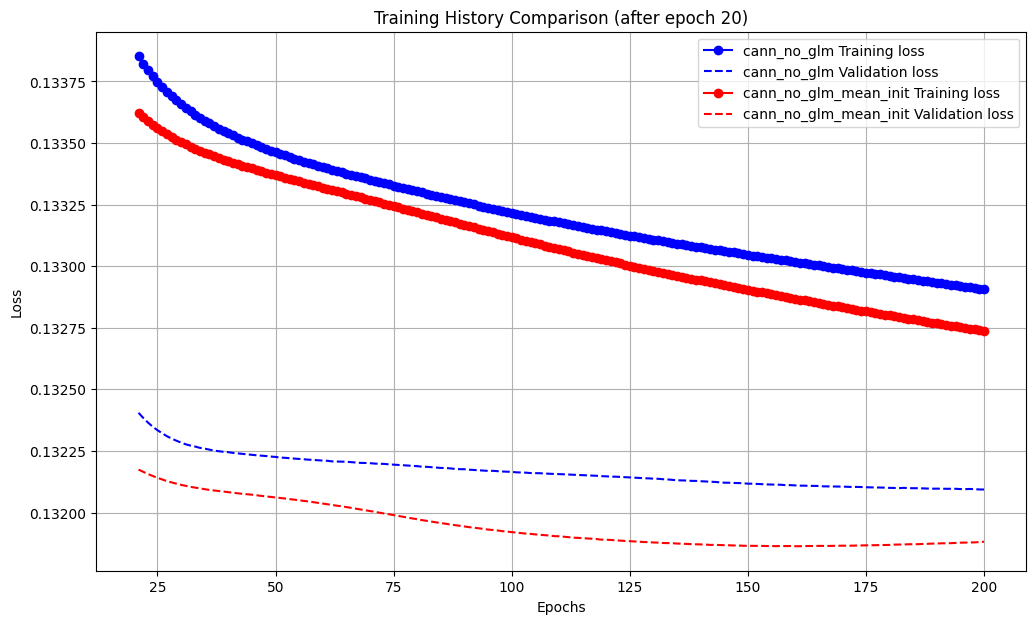

In [ ]:
plot_history2(model_list[-2], model_list[-1], 20)

In [ ]:
def create_mixed(seed, n_features, hidden_layers, kk, bb, kernel_regularizer, n_glm_features, glm_initializer):
    tf.keras.backend.clear_session()
    tf.keras.utils.set_random_seed(seed)

    fnn_linear_predictor, design_input = create_fnn_linear_predictor(n_features, hidden_layers, kk, bb, kernel_regularizer, final_bias=False)
    glm_linear_predictor, glm_input = create_glm_linear_predictor(n_glm_features, glm_initializer)

    linear_predictor = keras.layers.Add()([fnn_linear_predictor, glm_linear_predictor])

    output = keras.layers.Activation("exponential")(linear_predictor)

    model = keras.Model(inputs=[design_input, glm_input], outputs=output)

    return model

def regularized_glm_nn(name, data, fnn_initializer, glm_initializer, split, batch_size, epochs, keep_best, reg, description, seed=1234):
    tf.keras.utils.set_random_seed(seed)

    model_info = SimpleNamespace(
        name=name,
        description=description,
        constructor='regularized_glm_nn',
        fnn_initializer=fnn_initializer,
        glm_initializer=glm_initializer,
        split=split,
        batch_size=batch_size,
        epochs=epochs,
        keep_best=keep_best,
        seed=seed,
        regularizer = str(reg),
        train = SimpleNamespace(target = y_learn,
                            exposure = mtpl.training_data['Exposure'],
                            input = (X_learn, mtpl.training_data_1h)),
        test = SimpleNamespace(target = y_test,
                          exposure = mtpl.testing_data['Exposure'],
                          input = (X_test, mtpl.testing_data_1h)),
    )

    l2_reg = keras.regularizers.L2(reg)

    HIDDEN = [20, 15, 10]
    M_FEAT = X_learn.shape[1]
    KK = [len(mtpl.training_data_raw['VehBrand'].unique()), len(mtpl.training_data_raw['Region'].unique())]
    BB  = [2,2]

    glm_init = None
    if glm_initializer is not None:
      glm_init = glm_to_keras(glm_initializer.results.params, mtpl.training_data_1h.columns)

    n_glm_features = mtpl.training_data_1h.shape[1]

    # Pass glm parameters to create_mixed
    model_info.model = create_mixed(seed, M_FEAT, HIDDEN, KK, BB, l2_reg, n_glm_features, glm_init)

    if fnn_initializer == 'zero':
      fnn_layer = model_info.model.get_layer("fnn_linear_predictor")
      w0 = fnn_layer.get_weights()
      #w0[-2] *= 0
      #w0[-1] *= 0
      fnn_layer.set_weights([np.zeros_like(w) for w in w0])

    if epochs is not None:
      callbacks = [OneLineProgress()]
      if keep_best:
        callbacks.append(keras.callbacks.EarlyStopping(
          monitor="val_loss" if split else "loss",
          patience=epochs,          # effectively prevents early stopping
          restore_best_weights=True,
        ))

      model_info.model.compile(loss="poisson", optimizer="nadam")
      model_info.history = model_info.model.fit(
        model_info.train.input,
        model_info.train.target / model_info.train.exposure,
        sample_weight=model_info.train.exposure,
        validation_split=split,
        batch_size=batch_size,
        epochs=effective_epochs(epochs),
        verbose=0,
        callbacks=callbacks,
      )
    model_info.train.prediction = model_info.model(model_info.train.input, training=False).numpy()
    model_info.test.prediction = model_info.model(model_info.test.input, training=False).numpy()
    calculate_deviance(model_info)
    return model_info

In [ ]:
# Re-run the regularized GLM-NN model with the fixed function signature
model_list.append(regularized_glm_nn('rglnn', mtpl, 'zero', glm1, 0.1, 5000, 200, True, 0.1, 'regularized with L2=0.1'))

Epoch 200/200 - loss: 0.138466  - val_loss: 0.137514
Training Deviance = 46.967 Keras Poisson = 0.13839  Total Actual Claims: 23738.00  Total Predicted Claims: 22851.54  Relative Scoring (Actual / Predicted): 1.0388
Testing Deviance = 47.197 Keras Poisson = 0.13878  Total Actual Claims: 2645.00  Total Predicted Claims: 2551.47  Relative Scoring (Actual / Predicted): 1.0367


In [ ]:
model_list.append(regularized_glm_nn('rglnn_no_train', mtpl, 'zero', glm1, 0.1, 5000, None, True, 0.1, 'glm initialized rglnn'))

Training Deviance = 46.954 Keras Poisson = 0.13835  Total Actual Claims: 23738.00  Total Predicted Claims: 23738.00  Relative Scoring (Actual / Predicted): 1.0000
Testing Deviance = 47.179 Keras Poisson = 0.13874  Total Actual Claims: 2645.00  Total Predicted Claims: 2650.74  Relative Scoring (Actual / Predicted): 0.9978


In [ ]:
for reg in [0.0, 0.00001, 0.0001, 0.0005, 0.001, 0.002, 0.005, 0.01, 0.1, 100]:
  model_list.append(regularized_glm_nn('rglnn', mtpl, 'zero', glm1, 0.1, 50000, 200, True, reg, f'regularized with L2={reg}'))

Epoch 200/200 - loss: 0.133298  - val_loss: 0.132096
Training Deviance = 44.986 Keras Poisson = 0.13316  Total Actual Claims: 23738.00  Total Predicted Claims: 23676.09  Relative Scoring (Actual / Predicted): 1.0026
Testing Deviance = 44.989 Keras Poisson = 0.13293  Total Actual Claims: 2645.00  Total Predicted Claims: 2654.86  Relative Scoring (Actual / Predicted): 0.9963
Epoch 200/200 - loss: 0.133687  - val_loss: 0.132353
Training Deviance = 45.011 Keras Poisson = 0.13322  Total Actual Claims: 23738.00  Total Predicted Claims: 23536.25  Relative Scoring (Actual / Predicted): 1.0086
Testing Deviance = 44.952 Keras Poisson = 0.13283  Total Actual Claims: 2645.00  Total Predicted Claims: 2637.94  Relative Scoring (Actual / Predicted): 1.0027
Epoch 200/200 - loss: 0.134742  - val_loss: 0.133253
Training Deviance = 45.182 Keras Poisson = 0.13367  Total Actual Claims: 23738.00  Total Predicted Claims: 23334.75  Relative Scoring (Actual / Predicted): 1.0173
Testing Deviance = 45.105 Keras 

In [ ]:
QUICK_MODE = False

In [ ]:
model_info = model_list[-1]
intermediate_model = keras.Model(
    inputs=model_info.model.inputs,
    outputs=[
        model_info.model.get_layer("glm_linear_predictor").output,
        model_info.model.get_layer("fnn_linear_predictor").output,
        model_info.model.output,
    ]
)

glm_eta, fnn_eta, prediction = intermediate_model.predict(
    model_info.train.input
)

19069/19069 ━━━━━━━━━━━━━━━━━━━━ 24s 1ms/step


In [ ]:
fnn_eta

array([[2.474602e-07],
       [2.474602e-07],
       [2.474602e-07],
       ...,
       [2.474602e-07],
       [2.474602e-07],
       [2.474602e-07]], dtype=float32)

In [ ]:
results_data = []

for model_info in model_list:
    train_actual_claims = np.asarray(model_info.train.target).ravel()
    train_exposure = np.asarray(model_info.train.exposure).ravel()
    train_predicted_rates = np.asarray(model_info.train.prediction).ravel()
    train_predicted_claims = train_predicted_rates * train_exposure
    train_relative_scoring = train_actual_claims.sum() / train_predicted_claims.sum()

    test_actual_claims = np.asarray(model_info.test.target).ravel()
    test_exposure = np.asarray(model_info.test.exposure).ravel()
    test_predicted_rates = np.asarray(model_info.test.prediction).ravel()
    test_predicted_claims = test_predicted_rates * test_exposure
    test_relative_scoring = test_actual_claims.sum() / test_predicted_claims.sum()

    results_data.append({
        'name': getattr(model_info, 'name', None),
        'initializer': getattr(model_info, 'initializer', None),
        'fnn_initializer': getattr(model_info, 'fnn_initializer', None),
        'glm_initializer': getattr(getattr(model_info, 'glm_initializer', None), 'name', None),
        'batch_size': getattr(model_info, 'batch_size', None),
        'epochs': getattr(model_info, 'epochs', None),
        'keep_best': getattr(model_info, 'keep_best', None),
        'split': getattr(model_info, 'split', None),
        'regularizer': getattr(model_info, 'regularizer', None),
        'train_deviance': getattr(model_info.train, 'deviance', None),
        'train_relative_scoring': train_relative_scoring,
        'test_deviance': getattr(model_info.test, 'deviance', None),
        'test_relative_scoring': test_relative_scoring
    })

results_df = pd.DataFrame(results_data)
display(results_df)

,name,initializer,fnn_initializer,glm_initializer,batch_size,epochs,keep_best,split,regularizer,train_deviance,train_relative_scoring,test_deviance,test_relative_scoring
0,glm1,None,None,None,NaN,NaN,None,NaN,None,46.953720,1.000000,47.178625,0.997834
1,glm_keras_control,glm1,None,None,NaN,NaN,False,NaN,None,46.953720,1.000000,47.178625,0.997834
2,glm_keras_trained,None,None,None,5000.0,200.0,True,NaN,None,46.961176,1.009486,47.200002,1.007197
3,glm_keras_train_init,glm1,None,None,5000.0,20.0,False,NaN,None,46.955965,1.010982,47.188533,1.008840
4,glm_keras_trained,None,None,None,5000.0,200.0,True,0.1,None,47.004507,1.033826,47.250422,1.031282
5,glm_keras_train_init,glm1,None,None,5000.0,20.0,False,0.1,None,46.966795,1.038821,47.196992,1.036688
6,glm_keras_trained,None,None,None,50000.0,2000.0,True,NaN,None,46.954512,1.002555,47.174250,1.000332
7,glm_keras_train_init,glm1,None,None,50000.0,200.0,False,NaN,None,46.954442,1.002634,47.173778,1.000420
8,glm_keras_trained,None,None,None,50000.0,2000.0,True,0.1,None,46.988926,0.994238,47.233213,0.991769
9,glm_keras_train_init,glm1,None,None,50000.0,200.0,False,0.1,None,46.954579,0.998705,47.182034,0.996631


In [ ]:
print(results_df.to_csv())

,name,initializer,fnn_initializer,glm_initializer,batch_size,epochs,keep_best,split,regularizer,train_deviance,train_relative_scoring,test_deviance,test_relative_scoring
0,glm1,,,,,,,,,46.953719918266934,1.000000000000001,47.178624614533234,0.9978337569528632
1,glm_keras_control,glm1,,,,,False,,,46.953719935124305,1.0000000629130308,47.178624604424336,0.9978338203548712
2,glm_keras_trained,None,,,5000.0,200.0,True,,,46.96117642535264,1.0094858024155853,47.200002496867995,1.0071965766063322
3,glm_keras_train_init,glm1,,,5000.0,20.0,False,,,46.95596468507725,1.010982499992299,47.18853305760207,1.0088397222721763
4,glm_keras_trained,None,,,5000.0,200.0,True,0.1,,47.00450689481654,1.0338262493770947,47.25042193099254,1.0312819368934714
5,glm_keras_train_init,glm1,,,5000.0,20.0,False,0.1,,46.96679549684747,1.0388213993298698,47.19699152858665,1.036688234236075
6,glm_keras_trained,None,,,50000.0,2000.0,True,,,46.95451244373958,1.002555039428058,47.1742495534606,1.0003317047811966
7,glm_keras